### Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?

2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?


In [83]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 6)
pd.set_option("display.max_columns", None)

In [84]:
amz_raw = pd.read_csv("../lab-eda-univariate/amz_uk_price_prediction_dataset.csv")

In [85]:
amz = amz_raw.copy()

In [86]:
amz["category"].value_counts().head(5)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

In [87]:
amz.isna().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [88]:
print("duplicte, rows:", amz.duplicated().sum())

duplicte, rows: 0


2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?


In [89]:
amz.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


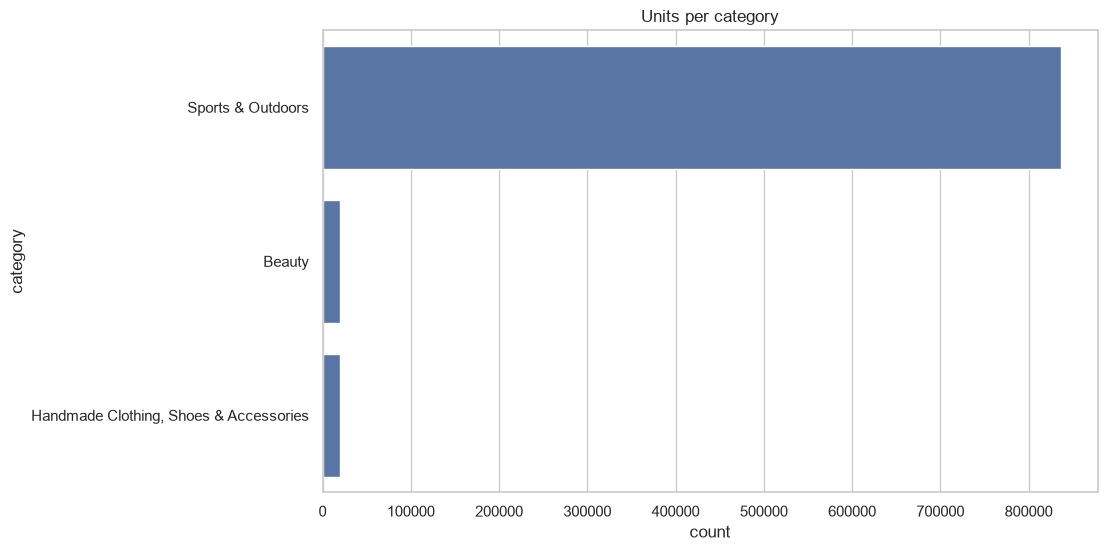

In [90]:
top_categories = amz["category"].value_counts().head(3).index
sns.countplot(data=amz, y="category", order = top_categories)
plt.title("Units per category")
plt.show()

<Axes: >

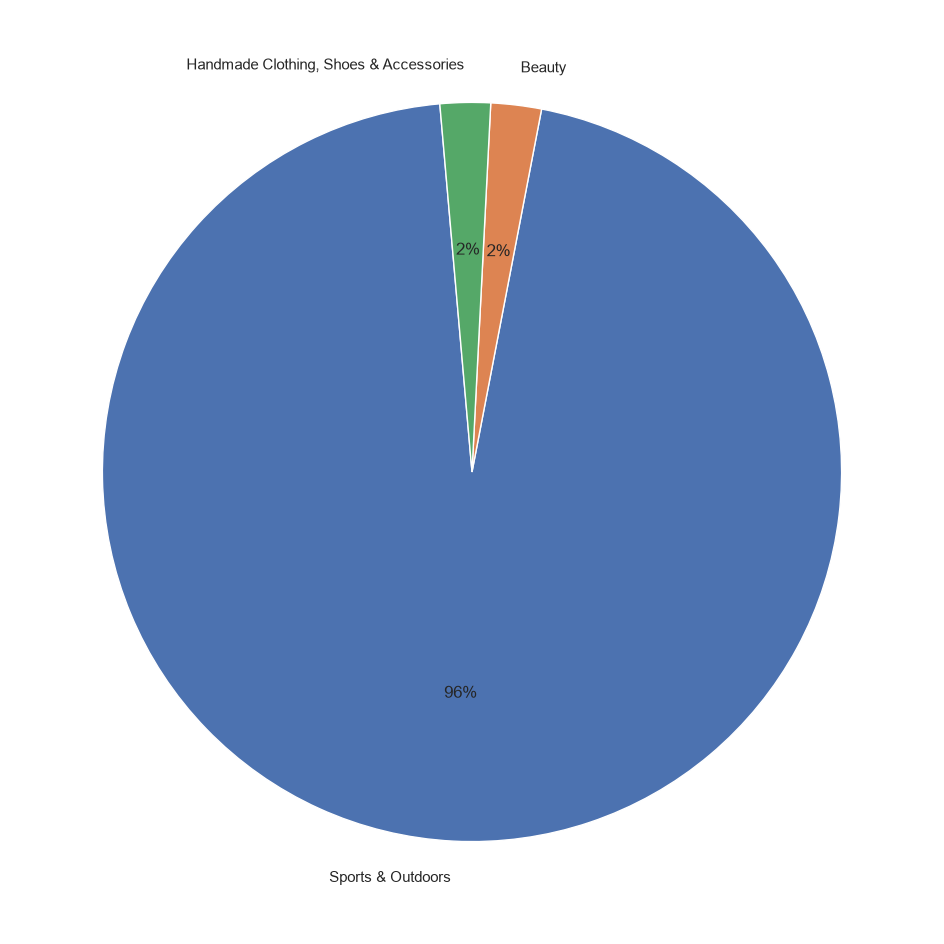

In [91]:
amz["category"].value_counts().head(3).plot.pie(autopct="%1.0f%%", startangle=95, figsize=(12,12))

In [92]:
"""""Sports and outdoors clearly dominates the listings"""

'""Sports and outdoors clearly dominates the listings'

### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 


In [93]:
price_of_product = amz["price"]

print( f"mean = {price_of_product.mean():.0f} | median = {price_of_product.median():.0f}    |  mode = {price_of_product.mode().tolist()}")

mean = 89 | median = 19    |  mode = [9.99]


In [94]:
""""The  mean is much higher than the mode, likely due to expensive product pulling the mean upward."""

'"The  mean is much higher than the mode, likely due to expensive product pulling the mean upward.'

In [95]:
print(f"variance = {price_of_product.var():.2f}  | standard deviation = {price_of_product.std():.2f}  | range = {price_of_product.max() - price_of_product.min():.2f}  | IQR = {price_of_product.quantile(0.75) - price_of_product.quantile(0.25):.2f} ")

variance = 119445.49  | standard deviation = 345.61  | range = 100000.00  | IQR = 36.00 


In [96]:
"""Product prices are highly varied and right-skewed, suggesting that a smaller number of expensive products are pulling the average upwards."""

'Product prices are highly varied and right-skewed, suggesting that a smaller number of expensive products are pulling the average upwards.'

C:\Users\Utilizador\AppData\Local\Temp\ipykernel_25948\968584751.py:14: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(price_of_product, vert=False)


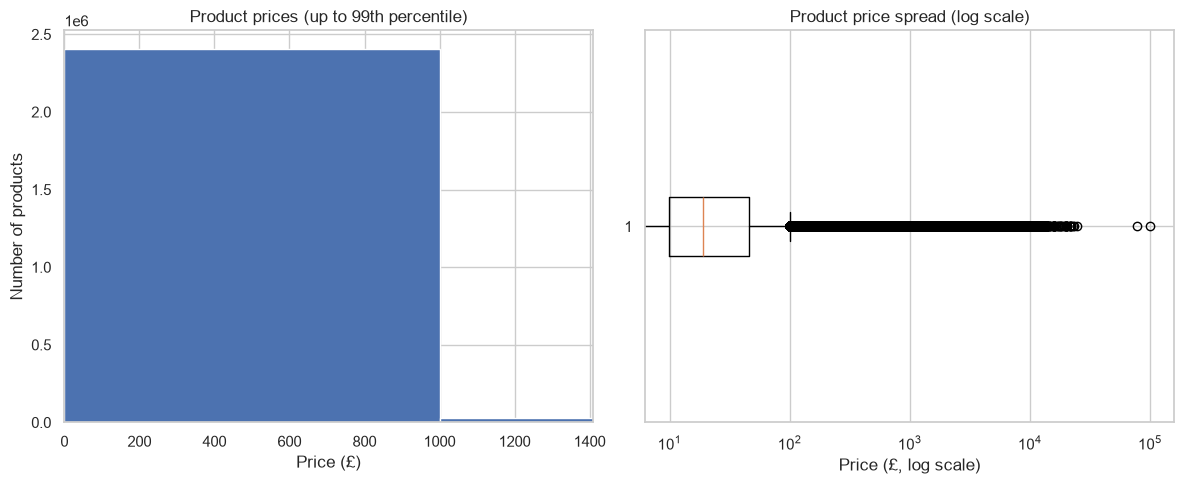

In [97]:
price_of_product = amz["price"].dropna()
price_99th = price_of_product.quantile(0.99)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Histogram zoomed to show the majority of prices
axes[0].hist(price_of_product, bins=100)
axes[0].set_xlim(0, price_99th)
axes[0].set_title("Product prices (up to 99th percentile)")
axes[0].set_xlabel("Price (£)")
axes[0].set_ylabel("Number of products")

# Full price distribution; log scale makes the long tail easier to see
axes[1].boxplot(price_of_product, vert=False)
axes[1].set_xscale("log")
axes[1].set_title("Product price spread (log scale)")
axes[1].set_xlabel("Price (£, log scale)")

plt.tight_layout()
plt.show()

In [98]:
#The price distribution is concentrated toward the lower end and is strongly right-skewed. The most common price is £9.99, and the median is £19, so half of the listed products cost £19 or less. A small number of much more expensive products pull the average up to about £89.
#The box plot should show high-price outliers, indicating that some products are priced significantly above the typical listing. If the histogram is difficult to read, it’s because those expensive prices stretch the horizontal axis; zoom in on the main price range or use a logarithmic scale to make the lower-priced products easier to compare.

### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

In [106]:
rating_of_product = amz["stars"]
rated = rating_of_product[rating_of_product >0]

print( f"mean = {rated.mean():.2f} | median = {rated.median():.2f}    |  mode = {rated.mode().tolist()}")

mean = 4.32 | median = 4.40    |  mode = [4.5]


In [ ]:
# the most frequent rating is 4.5

In [107]:
print(f"variance = {rated.var():.2f}  | standard deviation = {rated.std():.2f}  | range = {rated.max() - rated.min():.2f}  | IQR = {rated.quantile(0.75) - rated.quantile(0.25):.2f} ")

variance = 0.31  | standard deviation = 0.56  | range = 4.00  | IQR = 0.50 


In [ ]:
#the ratings biiger thant 0 are consistent

In [109]:
print(f"Skewness: {rated.skew():.2f}")
print(f"Kurtosis: {rated.kurtosis():.2f}")

Skewness: -2.38
Kurtosis: 9.78


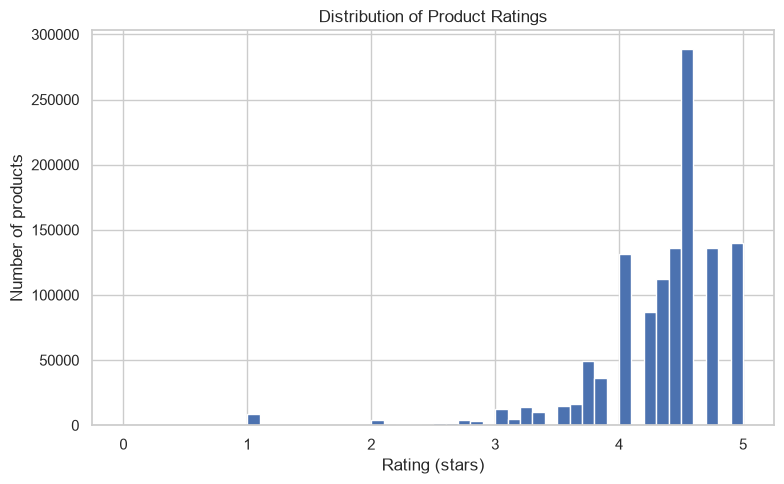

In [120]:
rated = amz.loc[amz["stars"] > 0, "stars"]

plt.figure(figsize=(8, 5))
plt.hist(rated, bins=50, range=(0, 5), edgecolor="white")
plt.title("Distribution of Product Ratings")
plt.xlabel("Rating (stars)")
plt.ylabel("Number of products")
plt.xticks(range(6))
plt.tight_layout()
plt.show()

In [ ]:
# 4.5 is the most common rating